# Analysis Preparation - Catalog CAP Lab

Prepares the seeded dataset for downstream experiments:
structure checks, missing values, duplicates, distribution statistics,
and the derived tables consumed by the hot-partition and consistency
analyses (`src/catalog_analysis/`).

Input: `data/sample/` (committed 5k-row sample) - point `DATA_DIR` at
`data/full/` for the 500k experiment dataset.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("../data/sample")
PREPARED = Path("../results/prepared")
PREPARED.mkdir(parents=True, exist_ok=True)

manifest = json.loads((DATA_DIR / "manifest.json").read_text())
print("dataset origin:", manifest["origin"], "| seed:", manifest["seed"])
print("rows:", manifest["rows"])

dataset origin: simulated | seed: 42
rows: {'products': 5000, 'access_log': 15000, 'consistency_log': 6000}


## 1. Load the datasets

In [2]:
products = pd.read_csv(DATA_DIR / "products.csv")
access = pd.read_csv(DATA_DIR / "access_log.csv")
access["ts"] = pd.to_datetime(access["ts"], unit="ms")
consistency = pd.read_csv(DATA_DIR / "consistency_log.csv")
consistency["ts"] = pd.to_datetime(consistency["ts"], unit="ms")

for name, df in [("products", products), ("access_log", access),
                 ("consistency_log", consistency)]:
    print(f"{name}: {df.shape[0]:,} rows x {df.shape[1]} cols")
    display(df.head(3))

products: 5,000 rows x 11 cols


,category_id,bucket,added_at,product_id,name,brand,price,currency,stock,rating,attributes
0,gaming,2,1768894498390,80caf18a-67d2-5d1a-81cd-e11dc27ecb1f,Pro Novel Plus,brand-060,4188.02,USD,1555,2.4,"{""color"": ""gold"", ""size"": ""XS""}"
1,pets,0,1769733493316,20cfbd62-6040-5a5c-ab94-60060cc0fb75,Eco Snack Set,brand-055,1329.05,USD,635,2.8,"{""color"": ""red"", ""size"": ""XL""}"
2,pets,1,1767392063354,892492a7-84a8-5d47-a4da-18d8b2ce52e9,Pro Novel Plus,brand-034,3081.79,USD,1566,1.9,"{""color"": ""blue"", ""size"": ""one-size""}"


access_log: 15,000 rows x 6 cols


,ts,request_id,op,category_id,product_id,latency_ms
0,2026-01-01 00:06:46.576,req-0000000,READ,health,ceee6b5c-6559-5fd8-8bc5-5b6dbb3af2c3,7.652
1,2026-01-01 00:16:52.955,req-0000001,READ,sports,61065f64-a206-546f-9f67-b30e4726d2d6,15.096
2,2026-01-01 00:19:39.771,req-0000002,READ,music,29587663-82d7-5f7d-b64b-097a506c369f,5.402


consistency_log: 6,000 rows x 7 cols


,ts,event,key,version,consistency_level,node,network_state
0,2026-01-01 00:02:09.371,WRITE,9b4be939-3794-50e9-a66b-283e75075593,1,QUORUM,node2,NORMAL
1,2026-01-01 00:02:24.983,WRITE,a40207da-9949-5e22-af7f-428f4dbbe4bf,1,ONE,node4,NORMAL
2,2026-01-01 00:08:37.942,WRITE,66e824de-2ea1-5c95-b9fb-0698324b5064,1,ONE,node5,NORMAL


## 2. Structure check
Expected columns per `docs/data-dictionary.md`.

In [3]:
EXPECTED = {
    "products": ["category_id", "bucket", "added_at", "product_id", "name",
                 "brand", "price", "currency", "stock", "rating", "attributes"],
    "access_log": ["ts", "request_id", "op", "category_id", "product_id",
                   "latency_ms"],
    "consistency_log": ["ts", "event", "key", "version", "consistency_level",
                        "node", "network_state"],
}
for name, df in [("products", products), ("access_log", access),
                 ("consistency_log", consistency)]:
    missing = set(EXPECTED[name]) - set(df.columns)
    extra = set(df.columns) - set(EXPECTED[name])
    print(f"{name}: missing={missing or 'none'}, extra={extra or 'none'}")
products.dtypes

products: missing=none, extra=none
access_log: missing=none, extra=none
consistency_log: missing=none, extra=none


category_id        str
bucket           int64
added_at         int64
product_id         str
name               str
brand              str
price          float64
currency           str
stock            int64
rating         float64
attributes         str
dtype: object

## 3. Missing values

In [4]:
for name, df in [("products", products), ("access_log", access),
                 ("consistency_log", consistency)]:
    na = df.isna().sum()
    na = na[na > 0]
    print(f"{name}: {dict(na) if len(na) else 'no missing values'}")

products: no missing values
access_log: no missing values
consistency_log: no missing values


## 4. Duplicate check
Duplicates of `product_id` and of both schema primary keys.

In [5]:
dup_pid = products["product_id"].duplicated().sum()
dup_pk_a = products[["category_id", "added_at", "product_id"]].duplicated().sum()
dup_pk_b = products[["category_id", "bucket", "added_at", "product_id"]].duplicated().sum()
dup_req = access["request_id"].duplicated().sum()
print(f"product_id dups: {dup_pid} | PK-A dups: {dup_pk_a} | "
      f"PK-B dups: {dup_pk_b} | request_id dups: {dup_req}")
assert dup_pid == dup_pk_a == dup_pk_b == dup_req == 0

product_id dups: 0 | PK-A dups: 0 | PK-B dups: 0 | request_id dups: 0


## 5. Distribution statistics

In [6]:
cat_rows = products["category_id"].value_counts()
cat_reqs = access["category_id"].value_counts()
summary = pd.DataFrame({
    "products": cat_rows,
    "row_share": cat_rows / len(products),
    "requests": cat_reqs,
    "request_share": cat_reqs / len(access),
}).sort_values("requests", ascending=False)
display(summary.head(10))
print(products[["price", "stock", "rating"]].describe())

,products,row_share,requests,request_share
category_id,,,,
health,440,0.0880,5313,0.354200
home-garden,73,0.0146,2304,0.153600
pets,1774,0.3548,1376,0.091733
movies,213,0.0426,1041,0.069400
music,41,0.0082,721,0.048067
toys,74,0.0148,612,0.040800
automotive,63,0.0126,464,0.030933
grocery,344,0.0688,410,0.027333
fashion,102,0.0204,358,0.023867


             price        stock       rating
count  5000.000000  5000.000000  5000.000000
mean   2523.507998  1018.421200     2.990680
std    1453.190253   582.053776     1.156805
min       5.100000     0.000000     1.000000
25%    1263.145000   512.750000     2.000000
50%    2550.930000  1031.000000     3.000000
75%    3788.807500  1532.000000     4.000000
max    4996.800000  2000.000000     5.000000


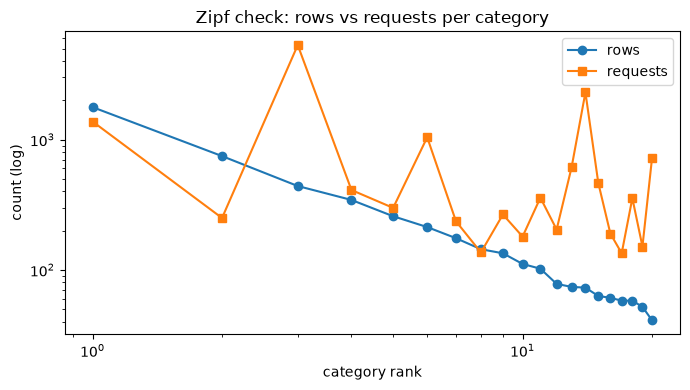

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
rank = np.arange(1, len(cat_rows) + 1)
ax.loglog(rank, cat_rows.values, "o-", label="rows")
ax.loglog(rank, cat_reqs.reindex(cat_rows.index).values, "s-", label="requests")
ax.set_xlabel("category rank"); ax.set_ylabel("count (log)")
ax.set_title("Zipf check: rows vs requests per category")
ax.legend(); fig.tight_layout(); plt.show()

## 6. Prepare hot-partition input

Per-partition request counts under both schemas:
Schema A partition = `category_id`; Schema B partition = `(category_id, bucket)`.

In [8]:
part_a = access.groupby("category_id")["op"].value_counts().unstack(fill_value=0)
part_a.columns = [c.lower() for c in part_a.columns]
part_a["total"] = part_a.sum(axis=1)

prod_lookup = products.set_index("product_id")["bucket"]
access["bucket"] = access["product_id"].map(prod_lookup)
part_b = access.groupby(["category_id", "bucket"])["op"].value_counts().unstack(fill_value=0)
part_b.columns = [c.lower() for c in part_b.columns]
part_b["total"] = part_b.sum(axis=1)

part_a.to_csv(PREPARED / "partition_loads_schema_a.csv")
part_b.reset_index().to_csv(PREPARED / "partition_loads_schema_b.csv", index=False)
print(f"Schema A partitions: {len(part_a)}, max/mean load = "
      f"{part_a['total'].max() / part_a['total'].mean():.2f}")
print(f"Schema B partitions: {len(part_b)}, max/mean load = "
      f"{part_b['total'].max() / part_b['total'].mean():.2f}")

Schema A partitions: 20, max/mean load = 7.08
Schema B partitions: 318, max/mean load = 9.43


## 7. Prepare consistency input

Latest committed version per key at read time -> ground truth the
stale-read analysis uses.

In [9]:
writes = consistency[consistency["event"] == "WRITE"]
latest_write = (writes.sort_values("ts")
                .groupby("key")["version"].last())
reads = consistency[consistency["event"] == "READ"].copy()
print(f"{len(writes)} writes / {len(reads)} reads, "
      f"{latest_write.size} versioned keys, "
      f"{(consistency['network_state'] == 'PARTITIONED').mean():.1%} of events during partition")
consistency.to_csv(PREPARED / "consistency_events.csv", index=False)

2954 writes / 3046 reads, 1287 versioned keys, 9.9% of events during partition


## 8. Summary

- Dataset loads cleanly, no missing values, no duplicate keys.
- Zipf skew confirmed: top categories dominate rows *and* requests.
- Prepared tables written to `results/prepared/` for
  `top_partitions.py`, `hot_partition_charts.py` and `stale_read.py`.